# BridgeRNA static gene embeddings

This first embedding benchmark asks whether the frozen, pre-contextual gene identity
vectors show interpretable organization. All numerical analysis is produced by
`pipeline/run_static_embeddings.py`; this notebook only loads saved outputs and
renders the report.

The analysis uses the canonical 15,165-gene order and the checkpoint tensor
`model_state_dict.gene_embedding.weight` (15,165 × 512). Average expression is the
arithmetic mean TPM across the **25,370 locally cached human samples that belong
to the model's training manifest**. This frozen reference subset is documented in
`training_expression_cohort.parquet`; it is not presented as the full 640,000-sample
training mean.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Image

HERE = Path.cwd()
if HERE.name != 'static_gene_embeddings':
    HERE = HERE / 'benchmarks/static_gene_embeddings'
RESULTS = HERE / 'results/static_embeddings'
analysis = pd.read_csv(RESULTS / 'gene_embedding_analysis.csv')
clusters = pd.read_csv(RESULTS / 'cluster_summary.csv')
go = pd.read_csv(RESULTS / 'go_enrichment.csv')
kegg = pd.read_csv(RESULTS / 'kegg_enrichment.csv')
provenance = json.loads((RESULTS / 'provenance.json').read_text())
assert len(analysis) == 15165 and analysis.gene.nunique() == 15165
assert set(analysis.cluster) == set(range(1, 11))
print(f"Genes: {len(analysis):,}; static dimensions: {provenance['embedding_shape'][1]}; "
      f"expression-reference samples: {provenance['expression']['samples']:,}")

Genes: 15,165; static dimensions: 512; expression-reference samples: 25,370


## Protocol and invariants

- t-SNE is run on a 50-component PCA representation of the static vectors with
  perplexity 30 and seed 42. It is a visualization only: global t-SNE distances
  are not interpreted.
- K-means is fit to the original, unscaled 512-dimensional vectors with `k=10`,
  50 initializations, and seed 42. Displayed cluster IDs are scikit-learn labels
  plus one; IDs are arbitrary names, not ranks.
- GO Biological Process and KEGG are tested independently by one-sided
  hypergeometric over-representation. The background is the canonical model
  vocabulary intersected with each library; BH correction is applied across all
  eligible terms within each cluster and library.
- TPM is reconstructed with `expm1` from an existing canonical natural
  `log1p(TPM)` cache before taking the arithmetic gene mean.

In [2]:
display(clusters.style.format({
    'mean_average_training_tpm': '{:,.2f}',
    'median_average_training_tpm': '{:,.2f}',
}))
display(pd.DataFrame({
    'quantity': ['training-reference samples', 'full training manifest', 'coverage',
                 'GO background', 'KEGG background'],
    'value': [provenance['expression']['samples'], provenance['expression']['full_training_samples'],
              f"{provenance['expression']['coverage_fraction']:.2%}",
              provenance['enrichment']['go']['annotated_background_genes'],
              provenance['enrichment']['kegg']['annotated_background_genes']]
}))

,cluster,genes,mean_average_training_tpm,median_average_training_tpm
0,1,1385,91.52,21.83
1,2,1478,58.25,21.09
2,3,1595,54.92,21.47
3,4,1592,66.54,22.52
4,5,1578,74.82,23.53
5,6,1590,78.78,22.46
6,7,1387,49.10,24.10
7,8,1549,63.81,21.80
8,9,1562,62.66,24.08
9,10,1449,58.98,20.70


,quantity,value
0,training-reference samples,25370
1,full training manifest,640000
2,coverage,3.96%
3,GO background,12692
4,KEGG background,6576


## Static embedding map colored by training expression

The color scale uses $\log_{10}(\mathrm{mean\ TPM}+0.001)$ for visibility, while
the saved table retains the unrounded arithmetic mean TPM. Any visible expression
gradient is descriptive association, not evidence that the embedding is merely an
expression lookup.

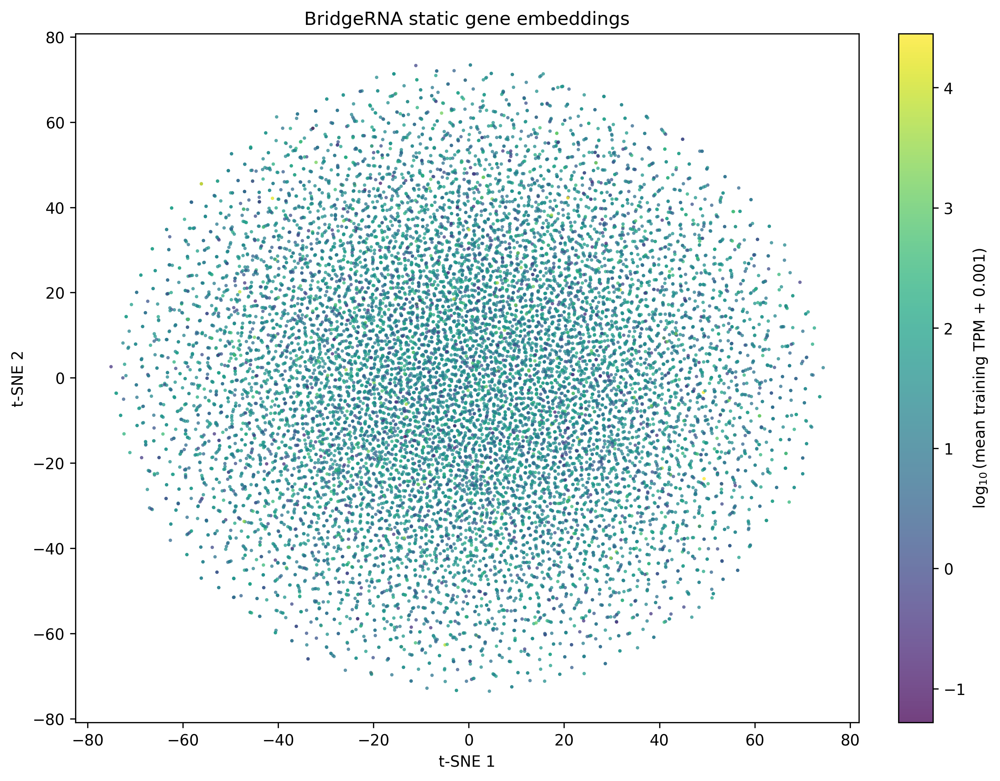

In [3]:
display(Image(filename=str(RESULTS / 'figures/tsne_by_training_tpm.png'))) 

In [4]:
analysis[['average_training_tpm', 'log10_average_training_tpm']].describe(
    percentiles=[.01, .1, .25, .5, .75, .9, .99])

,average_training_tpm,log10_average_training_tpm
count,15165.000000,15165.000000
mean,65.941312,1.268087
std,471.217970,0.667033
min,0.051418,-1.280519
1%,0.388115,-0.409922
10%,2.246568,0.351713
25%,7.097135,0.851144
50%,22.188662,1.346151
75%,50.143830,1.700226
90%,108.134175,2.033967


## K-means clusters displayed in t-SNE space

K-means operates in 512 dimensions; the following panel only projects those fixed
assignments onto t-SNE. Apparent separation or overlap in two dimensions is not the
clustering objective.

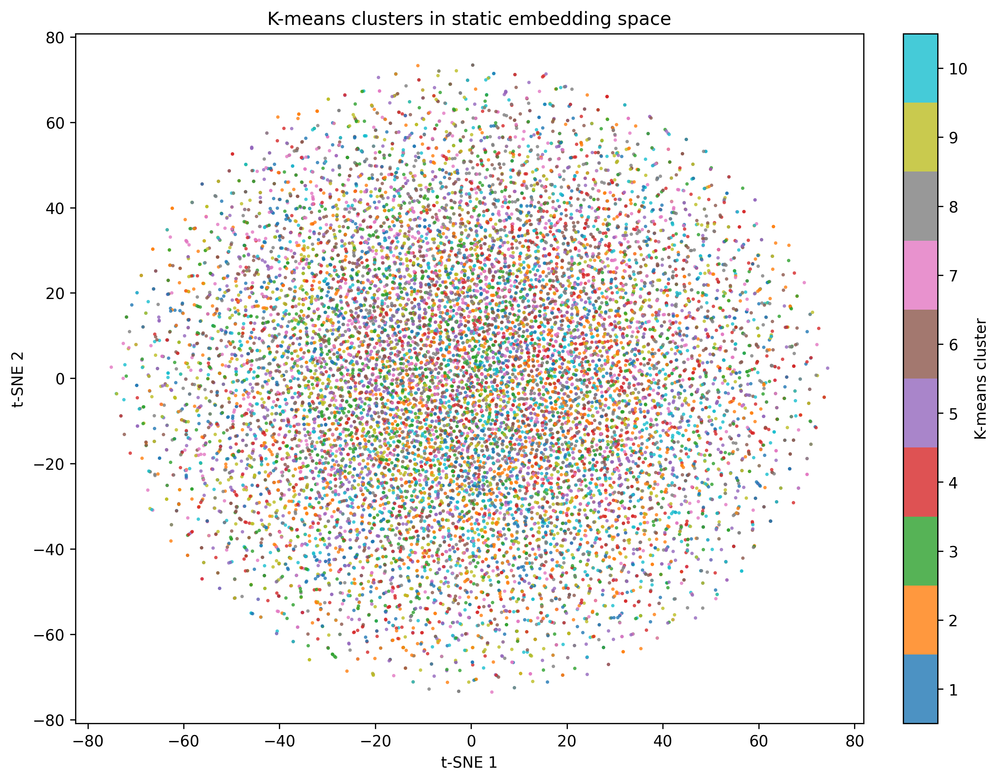

In [5]:
display(Image(filename=str(RESULTS / 'figures/tsne_by_cluster.png'))) 

## GO Biological Process enrichment for all clusters

The table reports the five lowest-FDR terms per cluster, including nonsignificant
results when a cluster has fewer than five discoveries. Full tested tables and
overlap genes are retained in `go_enrichment.csv`.

In [6]:
go_top = (go.sort_values(['cluster', 'fdr', 'p_value'])
          .groupby('cluster', group_keys=False).head(5)
          [['cluster', 'term', 'overlap_size', 'term_size', 'fdr', 'significant']])
display(go_top.style.format({'fdr': '{:.2e}'}))
print('Significant GO terms per cluster:')
display(go.groupby('cluster').significant.sum().rename('FDR < 0.05').to_frame().T)

,cluster,term,overlap_size,term_size,fdr,significant
0,1,Negative Regulation of Microtubule Polymerization or Depolymerization (GO:0031111),10,34,1.00e+00,False
1,1,Negative Regulation of Microtubule Depolymerization (GO:0007026),8,23,1.00e+00,False
2,1,Negative Regulation of Supramolecular Fiber Organization (GO:1902904),16,73,1.00e+00,False
3,1,Regulation of Microtubule Depolymerization (GO:0031114),9,29,1.00e+00,False
4,1,Regulation of Microtubule Polymerization or Depolymerization (GO:0031110),9,30,1.00e+00,False
5614,2,Negative Regulation of Tumor Necrosis Factor Production (GO:0032720),12,36,5.56e-01,False
5615,2,Negative Regulation of Tumor Necrosis Factor Superfamily Cytokine Production (GO:1903556),12,38,5.56e-01,False
5616,2,Regulation of Autophagy (GO:0010506),35,214,1.00e+00,False
5617,2,Positive Regulation of mRNA Catabolic Process (GO:0061014),12,49,1.00e+00,False
5618,2,Cyclic Nucleotide Transport (GO:0070729),5,11,1.00e+00,False


Significant GO terms per cluster:


cluster,1,2,3,4,5,6,7,8,9,10
FDR < 0.05,0,0,0,0,0,0,0,0,0,0


### Requested GO comparison: clusters 6 and 9

Bars show the ten lowest-FDR terms in each selected cluster. The dashed line is
FDR 0.05; gray bars do not cross it.

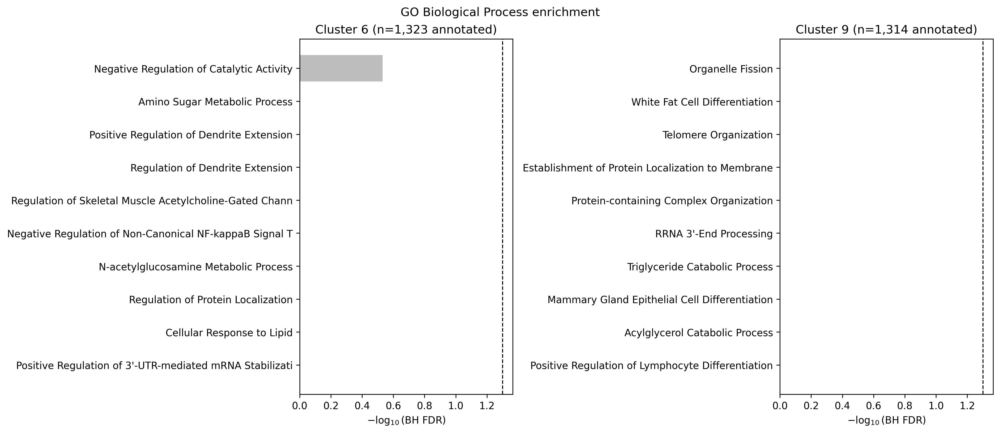

In [7]:
display(Image(filename=str(RESULTS / 'figures/go_clusters_6_9.png'))) 

In [8]:
display(go.loc[go.cluster.isin([6, 9])].sort_values(['cluster','fdr'])
        .groupby('cluster', group_keys=False).head(10)
        [['cluster','term','overlap_size','cluster_annotated_size','term_size','fdr','overlap_genes']]
        .style.format({'fdr':'{:.2e}'}))

,cluster,term,overlap_size,cluster_annotated_size,term_size,fdr,overlap_genes
28070,6,Negative Regulation of Catalytic Activity (GO:0043086),13,1323,37,2.94e-01,ABL1;CAND1;EIF4A2;GNAI3;GRM3;GSK3B;HNRNPU;MT3;NES;PPP1R12A;PRDX3;TMBIM1;TP53
28071,6,Amino Sugar Metabolic Process (GO:0006040),7,1323,17,1.00e+00,CHST2;CHST7;CSGALNACT1;EXTL2;LARGE1;MGAT3;SLC35A3
28072,6,Positive Regulation of Dendrite Extension (GO:1903861),7,1323,17,1.00e+00,CPNE5;CPNE6;ITSN2;RASAL1;RNF157;SMURF1;SYT4
28073,6,Regulation of Dendrite Extension (GO:1903859),7,1323,18,1.00e+00,CPNE5;CPNE6;ITSN2;RASAL1;RNF157;SMURF1;SYT4
28074,6,Regulation of Skeletal Muscle Acetylcholine-Gated Channel Clustering (GO:1904393),4,1323,7,1.00e+00,FZD9;LAMA1;LAMB1;LARGE1
28075,6,Negative Regulation of Non-Canonical NF-kappaB Signal Transduction (GO:1901223),8,1323,26,1.00e+00,BCL3;C1QTNF3;DAB2IP;FOXJ1;NLRP12;NMI;PPM1A;PPM1B
28076,6,N-acetylglucosamine Metabolic Process (GO:0006044),5,1323,13,1.00e+00,CHST2;CHST7;EXTL2;LARGE1;MGAT3
28077,6,Regulation of Protein Localization (GO:0032880),19,1323,102,1.00e+00,ABCA2;CEP290;CTSD;DNAJB6;DZIP1L;FBXW7;GBF1;GSK3B;HSP90AA1;KCNAB2;MAP1A;PPM1F;TOR1A;TRIM46;TRIM67;USP8;VIM;VPS4A;ZDHHC7
28078,6,Cellular Response to Lipid (GO:0071396),31,1323,192,1.00e+00,ABCB4;ADCY6;ANKRD1;ATP1A1;ATP1A3;BPI;CCR5;CRHBP;DAB2IP;EGFR;GSK3B;IL18;IL18R1;INSIG1;LY96;LYN;MMP8;NFKBIB;NR1H4;NR3C1;PYCARD;RET;SPP1;TFPI;TICAM1;TRAF6;UPF1;VIM;WNT7B;WNT9B;ZNF703
28079,6,Positive Regulation of 3'-UTR-mediated mRNA Stabilization (GO:1905870),3,1323,5,1.00e+00,RBM24;TENT4A;TENT4B


## KEGG enrichment for all clusters

The same frozen cluster assignments and library-specific measurable background are
used. Full tested results are retained in `kegg_enrichment.csv`.

In [9]:
kegg_top = (kegg.sort_values(['cluster', 'fdr', 'p_value'])
            .groupby('cluster', group_keys=False).head(5)
            [['cluster', 'term', 'overlap_size', 'term_size', 'fdr', 'significant']])
display(kegg_top.style.format({'fdr': '{:.2e}'}))
print('Significant KEGG terms per cluster:')
display(kegg.groupby('cluster').significant.sum().rename('FDR < 0.05').to_frame().T)

,cluster,term,overlap_size,term_size,fdr,significant
0,1,D-AMINO ACID METABOLISM,3,5,1.00e+00,False
1,1,VIRAL CARCINOGENESIS,23,152,1.00e+00,False
2,1,PRION DISEASE,30,220,1.00e+00,False
3,1,CHEMICAL CARCINOGENESIS - REACTIVE OXYGEN SPECIES,24,171,1.00e+00,False
4,1,MORPHINE ADDICTION,14,86,1.00e+00,False
348,2,HORMONE SIGNALING,27,196,1.00e+00,False
349,2,FOCAL ADHESION,26,188,1.00e+00,False
350,2,GALACTOSE METABOLISM,6,26,1.00e+00,False
351,2,"PARATHYROID HORMONE SYNTHESIS, SECRETION AND ACTION",16,104,1.00e+00,False
352,2,MELANOGENESIS,14,89,1.00e+00,False


Significant KEGG terms per cluster:


cluster,1,2,3,4,5,6,7,8,9,10
FDR < 0.05,0,0,0,0,0,0,0,0,0,0


### Requested KEGG comparison: clusters 2 and 7

Bars show the ten lowest-FDR terms in each selected cluster, with the same multiple-
testing threshold as above.

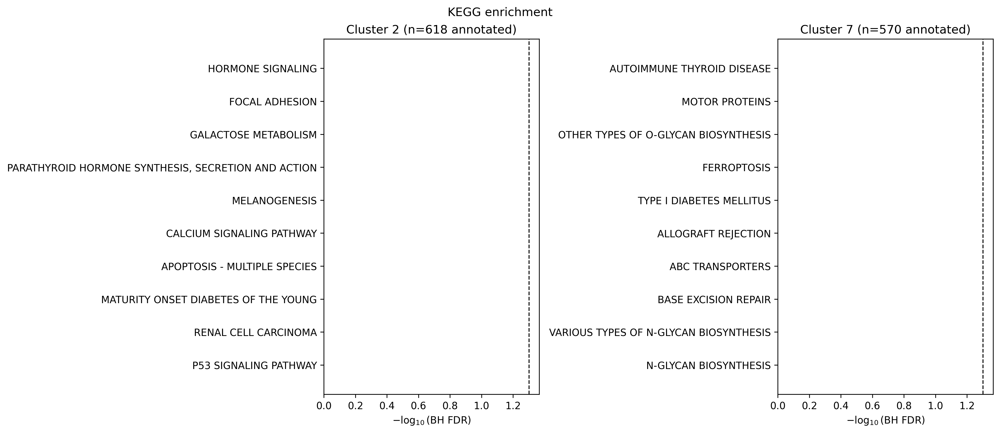

In [10]:
display(Image(filename=str(RESULTS / 'figures/kegg_clusters_2_7.png'))) 

In [11]:
display(kegg.loc[kegg.cluster.isin([2, 7])].sort_values(['cluster','fdr'])
        .groupby('cluster', group_keys=False).head(10)
        [['cluster','term','overlap_size','cluster_annotated_size','term_size','fdr','overlap_genes']]
        .style.format({'fdr':'{:.2e}'}))

,cluster,term,overlap_size,cluster_annotated_size,term_size,fdr,overlap_genes
348,2,HORMONE SIGNALING,27,618,196,1.00e+00,ADCY2;ADIPOQ;ADIPOR1;ADIPOR2;AMH;AVPR1B;AVPR2;CCKBR;DIO2;DRD2;DRD4;GCGR;GNA11;GNG5;GNRH1;GPER1;MC1R;MC3R;NPPC;PDYN;POMC;PRLHR;PRLR;SLCO1C1;SMAD1;STK11;TRHR
349,2,FOCAL ADHESION,26,618,188,1.00e+00,ACTN1;ARHGAP35;BCL2;BRAF;CAV2;CAV3;CCND2;COL1A2;COL6A3;COL9A1;CRKL;FN1;IBSP;ITGA2;MAPK1;PARVB;PARVG;PDGFD;PDGFRB;PDPK1;PKN1;PPP1CA;RAP1A;RAPGEF1;SHC4;TNR
350,2,GALACTOSE METABOLISM,6,618,26,1.00e+00,HOOK2;LALBA;MAP4K2;MGAM;PFKM;PMEL
351,2,"PARATHYROID HORMONE SYNTHESIS, SECRETION AND ACTION",16,618,104,1.00e+00,ADCY2;AKAP13;ARRB1;BCL2;BRAF;CASR;CREB3L2;EGR1;GCM1;GNA11;ITPR3;MAPK1;MEF2A;MEF2D;RXRG;STK39
352,2,MELANOGENESIS,14,618,89,1.00e+00,ADCY2;CALML3;CREB3L2;FZD4;FZD7;KITLG;MAPK1;MC1R;PARD3;POMC;TYRP1;WNT10A;WNT4;WNT9A
353,2,CALCIUM SIGNALING PATHWAY,30,618,234,1.00e+00,ADCY2;AVPR1B;CACNA1A;CALML3;CASQ2;CCKBR;FGF10;FGF16;FGF17;FGFR3;GNA11;GRIN2B;HTR6;ITPR3;NANOS2;NANOS3;NTRK3;P2RX6;PDGFD;PDGFRB;PHKA1;PHKA2;PHKB;SLC25A5;SLC8A1;SPHK2;TFEB;TGFA;TPCN1;TRHR
354,2,APOPTOSIS - MULTIPLE SPECIES,6,618,29,1.00e+00,BBC3;BCL2;BCL2L1;BECN1;DIABLO;TNFRSF1A
355,2,MATURITY ONSET DIABETES OF THE YOUNG,5,618,22,1.00e+00,FOXA3;HNF1A;MAFA;MAP4K2;MNX1
356,2,RENAL CELL CARCINOMA,10,618,63,1.00e+00,BRAF;CRKL;ETS1;MAPK1;PKN1;RAP1A;RAPGEF1;RBX1;TGFA;VHL
357,2,P53 SIGNALING PATHWAY,10,618,65,1.00e+00,BBC3;BCL2;BCL2L1;CCND2;CCNE2;CHEK2;GTSE1;MDM4;PIDD1;RCHY1


## Conclusion and limitations

This benchmark establishes a reproducible descriptive map of BridgeRNA's static
gene embedding and tests whether its deterministic k-means partitions concentrate
known GO and KEGG annotations. Enrichment supports functional organization only
where multiple-testing-adjusted results are present; it does not establish causal
biology or contextual behavior.

Major limitations are that t-SNE is nonlinear and local, k-means imposes spherical
Euclidean partitions, cluster numbers are arbitrary, gene-set databases are
incomplete and overlapping, and mean training TPM currently covers the 25,370
model-training samples available in the shared expression cache rather than all
640,000 training samples and contains no mouse samples. The next contextual-embedding subtask should use the same
gene vocabulary and explicitly separate sample context from this static baseline.

In [12]:
print(f"Adjusted enrichment discoveries: GO={int(go.significant.sum())}; "
      f"KEGG={int(kegg.significant.sum())}. Thus this static k-means analysis "
      "does not provide FDR-controlled functional enrichment evidence for any cluster.")

Adjusted enrichment discoveries: GO=0; KEGG=0. Thus this static k-means analysis does not provide FDR-controlled functional enrichment evidence for any cluster.


In [13]:
pd.DataFrame({'limitation': provenance['limitations']})

,limitation
0,the cached training-expression reference conta...
1,t-SNE preserves local neighborhoods but not gl...
2,k-means cluster identifiers are arbitrary dete...
3,enrichment is descriptive and does not validat...


# Extended static-space characterization

The following exploratory extension compares the unchanged static tensor, row-wise
L2 normalization, and post-hoc row-wise LayerNorm. LayerNorm is only a geometric
transformation of the checkpoint tensor; it is **not** evidence about a model
trained with embedding-level normalization. The screening profile uses three
seeds, K = 5/10/20, 10 annotation nulls, and one shuffled-vector null, so its tail
probabilities are deliberately coarse.

In [14]:
CHAR = HERE / 'results/static_characterization'
static_summary = pd.read_csv(CHAR / 'representation_summary.csv')
static_neighbors = pd.read_csv(CHAR / 'neighborhood_functional_overlap.csv')
static_agreement = pd.read_csv(CHAR / 'neighborhood_representation_agreement.csv')
display(static_summary[['representation','pca_participation_ratio','pcs_for_90pct',
 'silhouette','calinski_harabasz','cluster_stability_ari','significant_go_terms',
 'significant_kegg_terms']].style.format({
 'pca_participation_ratio':'{:.1f}','silhouette':'{:.4f}',
 'calinski_harabasz':'{:.2f}','cluster_stability_ari':'{:.4f}'}))

,representation,pca_participation_ratio,pcs_for_90pct,silhouette,calinski_harabasz,cluster_stability_ari,significant_go_terms,significant_kegg_terms
0,raw,495.1,443,-0.0003,13.43,0.0062,0,0
1,l2_cosine,495.1,443,0.0000,13.42,0.0045,0,4
2,layernorm,494.2,442,-0.0000,13.41,0.0058,2,0


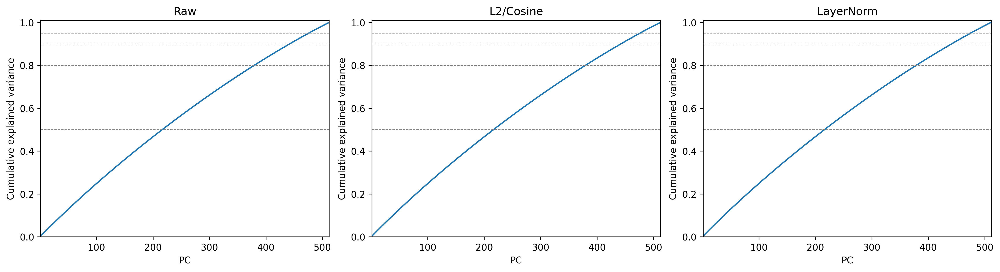

In [15]:
display(Image(filename=str(CHAR / 'pca_variance_spectra.png'))) 

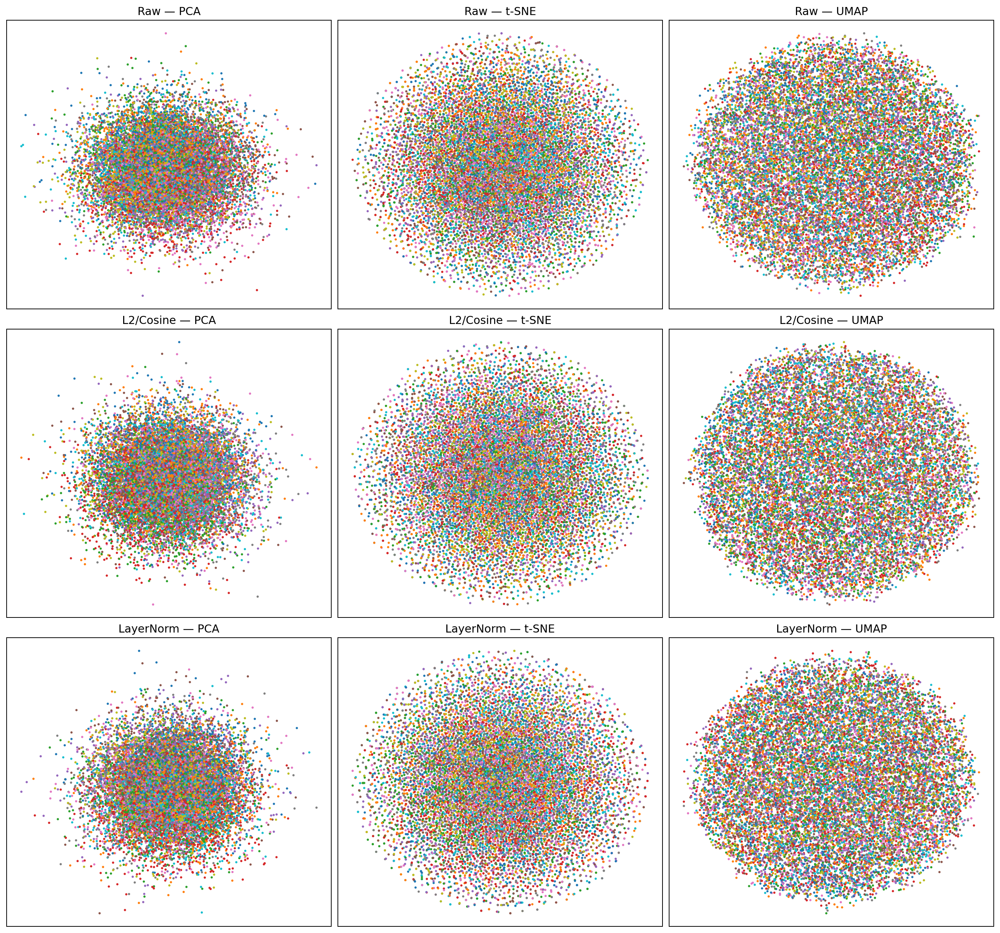

In [16]:
display(Image(filename=str(CHAR / 'geometry_projections.png'))) 

The embeddings are nearly full-dimensional: approximately 442–443 PCs are
needed for 90% variance, and the participation ratio is approximately 494–495 of
512. Silhouette scores are effectively zero and repeated K-means solutions have
ARI near 0.005. Thus the visually intermixed projections agree with the quantitative
absence of stable global partitions; the conclusion does not depend on t-SNE or
UMAP appearance.

In [17]:
display(static_neighbors[['representation','library','k','shared_pair_fraction',
 'null_mean','fold_over_null','empirical_p']].style.format({
 'shared_pair_fraction':'{:.4f}','null_mean':'{:.4f}','fold_over_null':'{:.3f}',
 'empirical_p':'{:.3f}'}))
display(static_agreement.style.format({'mean_neighbor_jaccard':'{:.3f}',
                                       'sd_neighbor_jaccard':'{:.3f}'}))

,representation,library,k,shared_pair_fraction,null_mean,fold_over_null,empirical_p
0,raw,GO,10,0.0705,0.0708,0.996,0.727
1,l2_cosine,GO,10,0.0710,0.0708,1.004,0.364
2,layernorm,GO,10,0.0713,0.0708,1.007,0.182
3,raw,GO,25,0.0706,0.0705,1.001,0.545
4,l2_cosine,GO,25,0.0707,0.0705,1.002,0.545
5,layernorm,GO,25,0.0710,0.0705,1.007,0.182
6,raw,GO,50,0.0712,0.0707,1.007,0.182
7,l2_cosine,GO,50,0.0712,0.0707,1.007,0.182
8,layernorm,GO,50,0.0712,0.0707,1.007,0.182
9,raw,KEGG,10,0.0522,0.0538,0.970,1.000


,representation_a,representation_b,k,mean_neighbor_jaccard,sd_neighbor_jaccard
0,raw,l2_cosine,10,0.211,0.101
1,raw,l2_cosine,25,0.233,0.066
2,raw,l2_cosine,50,0.254,0.049
3,raw,layernorm,10,0.210,0.101
4,raw,layernorm,25,0.232,0.066
5,raw,layernorm,50,0.252,0.049
6,l2_cosine,layernorm,10,0.900,0.119
7,l2_cosine,layernorm,25,0.908,0.083
8,l2_cosine,layernorm,50,0.916,0.069


Static local topology is also close to random (roughly 0.97–1.02× null).
L2 and post-hoc LayerNorm produce nearly the same neighbors (Jaccard ≈ 0.90–0.92),
whereas either shares only ≈ 0.21–0.25 with raw Euclidean neighborhoods. The few
global L2 KEGG or LayerNorm GO discoveries therefore occur without stable global
clusters or a broad local functional effect and should be treated as isolated
exploratory signals.

# Contextual-depth follow-up

This lightweight follow-up retains **individual gene tokens**—no sample-level mean
pooling. It uses one deterministic primary tumor from each of eight TCGA cohorts
(GBM, BRCA, LUAD, KIRC, LIHC, PRAD, COAD, and SKCM). L0 is the pure, sample-invariant
`gene_embedding.weight`; L1, L6, and L12 are the per-gene representations after the
corresponding transformer layer. Neighbors are other genes within the same sample,
which prevents trivial retrieval of the same gene from another sample.

Raw cosine and gene-wise mean-centered cosine are evaluated. Top-PC removal was
omitted from this lightweight screen. GO/KEGG use the same 15,165-gene universe at
every depth. Pair-retrieval negatives are annotation-degree-quartile matched.

,cohort,sample_id,sample_type
0,GBM,8B4E465B-0FD5-4154-824B-1E6B2656FD2F,Primary Tumor
1,BRCA,80B4E7D6-C931-426F-810E-B6059D2C6F15,Primary Tumor
2,LUAD,83453F80-8A68-4A3C-995D-85CFB1011249,Primary Tumor
3,KIRC,79A03652-6493-40E8-93EC-431B6D797F65,Primary Tumor
4,LIHC,7847E952-D2AD-4D55-A90A-21DEFCAA63D8,Primary Tumor
5,PRAD,846FECEB-E9B1-4E42-B5C6-8793C52A3DB6,Primary Tumor
6,COAD,81B60B5B-307F-4C3F-9508-CB1624D0925C,Primary Tumor
7,SKCM,799673ED-C935-4CE9-B8F3-14EE41C25BA1,Primary Tumor


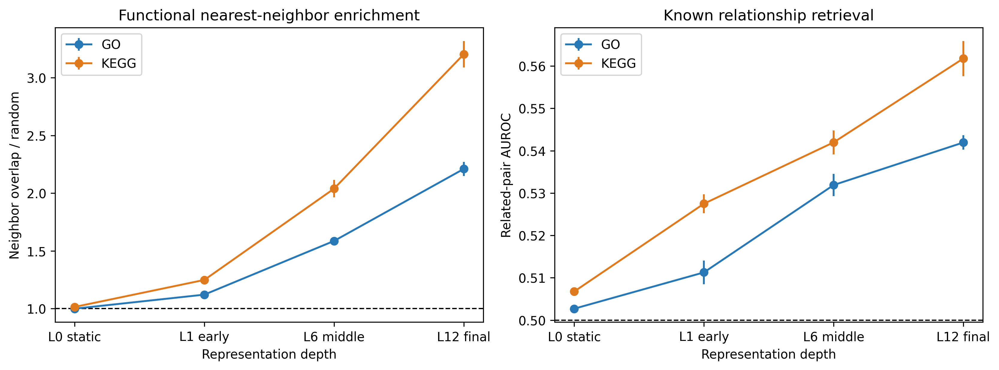

In [18]:
CTX = HERE / 'results/contextual_depth'
depth = pd.read_csv(CTX / 'layerwise_summary.csv')
contexts = pd.read_csv(CTX / 'selected_gene_context_dependence.csv')
examples = pd.read_csv(CTX / 'selected_gene_context_neighborhoods.csv')
display(pd.read_csv(CTX / 'sample_manifest.csv')[['cohort','sample_id','sample_type']])
display(Image(filename=str(CTX / 'contextual_depth_summary.png')))

In [19]:
order=['L0_static','L1_early','L6_middle','L12_final']
q=depth[(depth.geometry=='mean_centered_cosine') & (depth.k==25)].copy()
neighbor=q.pivot(index='layer',columns='library',values='neighbor_fold')
auc=q.pivot(index='layer',columns='library',values='related_pair_auroc')
table=pd.DataFrame(index=order)
table['GO neighbor enrichment']=neighbor['GO']
table['KEGG neighbor enrichment']=neighbor['KEGG']
table['GO related-pair AUROC']=auc['GO']
table['KEGG related-pair AUROC']=auc['KEGG']
table['Null expectation']='1.0× neighbors; AUROC 0.5'
display(table.style.format({c:'{:.3f}' for c in table.columns if c!='Null expectation'}))

,GO neighbor enrichment,KEGG neighbor enrichment,GO related-pair AUROC,KEGG related-pair AUROC,Null expectation
L0_static,0.999,1.014,0.503,0.507,1.0× neighbors; AUROC 0.5
L1_early,1.121,1.248,0.511,0.527,1.0× neighbors; AUROC 0.5
L6_middle,1.586,2.039,0.532,0.542,1.0× neighbors; AUROC 0.5
L12_final,2.210,3.204,0.542,0.562,1.0× neighbors; AUROC 0.5


The depth trend supports the stated hypothesis in this exploratory cohort.
For mean-centered cosine at k=25, GO neighborhood enrichment rises from ~1.00×
at L0 to 1.12×, 1.59×, and 2.21× at L1/L6/L12. KEGG rises from ~1.01× to
1.25×, 2.04×, and 3.20×. Related-pair AUROC increases more modestly—from near
chance at L0 to approximately 0.542 (GO) and 0.562 (KEGG) at L12. Raw cosine
shows the same ordering but weaker intermediate-layer effects, indicating that
anisotropy removal helps expose rather than create the depth trend.

In [20]:
display(depth[(depth.k==25)][['layer','geometry','library','neighbor_fold',
 'neighbor_fold_sd','related_pair_auroc','auroc_sd','pair_smd']]
 .sort_values(['geometry','library','layer']).style.format({
 'neighbor_fold':'{:.3f}','neighbor_fold_sd':'{:.3f}','related_pair_auroc':'{:.3f}',
 'auroc_sd':'{:.3f}','pair_smd':'{:.3f}'}))

,layer,geometry,library,neighbor_fold,neighbor_fold_sd,related_pair_auroc,auroc_sd,pair_smd
1,L0_static,mean_centered_cosine,GO,0.999,nan,0.503,nan,0.001
13,L12_final,mean_centered_cosine,GO,2.210,0.062,0.542,0.002,0.148
25,L1_early,mean_centered_cosine,GO,1.121,0.010,0.511,0.003,0.032
37,L6_middle,mean_centered_cosine,GO,1.586,0.033,0.532,0.003,0.107
4,L0_static,mean_centered_cosine,KEGG,1.014,nan,0.507,nan,0.022
16,L12_final,mean_centered_cosine,KEGG,3.204,0.115,0.562,0.004,0.220
28,L1_early,mean_centered_cosine,KEGG,1.248,0.036,0.527,0.002,0.094
40,L6_middle,mean_centered_cosine,KEGG,2.039,0.075,0.542,0.003,0.147
7,L0_static,raw_cosine,GO,0.999,nan,0.503,nan,0.001
19,L12_final,raw_cosine,GO,2.111,0.066,0.537,0.005,0.130


## Same-gene neighborhoods across contexts

The examples below quantify how top-10 centered-cosine neighborhoods for the same
anchor change across the eight tumors. Cross-context Jaccard below one demonstrates
context dependence; GO/KEGG coherence records whether changing neighbors still
share an annotation with the anchor. These examples are descriptive and are not
tissue-specific enrichment tests.

In [21]:
display(contexts.style.format({
 'mean_cross_context_neighbor_jaccard':'{:.3f}','go_coherent_fraction':'{:.3f}',
 'kegg_coherent_fraction':'{:.3f}'}))
display(examples[(examples.layer=='L12_final') & examples.anchor_gene.isin(['CD3D','ESR1','TP53'])]
 [['cohort','anchor_gene','rank','neighbor_gene','anchor_log1p_tpm','shares_go','shares_kegg']]
 .sort_values(['anchor_gene','cohort','rank']).head(90))

,layer,anchor_gene,mean_cross_context_neighbor_jaccard,contexts,go_coherent_fraction,kegg_coherent_fraction
0,L0_static,ALB,nan,1,0.000,0.000
1,L0_static,CD3D,nan,1,0.000,0.000
2,L0_static,ESR1,nan,1,0.300,0.000
3,L0_static,PAX8,nan,1,0.200,0.100
4,L0_static,TP53,nan,1,0.100,0.100
5,L12_final,ALB,0.378,8,0.025,0.000
6,L12_final,CD3D,0.302,8,0.450,0.438
7,L12_final,ESR1,0.063,8,0.325,0.163
8,L12_final,PAX8,0.199,8,0.175,0.062
9,L12_final,TP53,0.381,8,0.487,0.087


,cohort,anchor_gene,rank,neighbor_gene,anchor_log1p_tpm,shares_go,shares_kegg
1840,BRCA,CD3D,1,CD3G,0.848634,True,False
1890,BRCA,CD3D,1,CD3G,0.848634,True,False
1841,BRCA,CD3D,2,UBASH3A,0.848634,False,False
1891,BRCA,CD3D,2,UBASH3A,0.848634,False,False
1842,BRCA,CD3D,3,CD3E,0.848634,True,True
...,...,...,...,...,...,...,...
2192,LIHC,CD3D,3,TRAT1,0.220885,False,False
2143,LIHC,CD3D,4,CD27,0.220885,True,False
2193,LIHC,CD3D,4,CD27,0.220885,True,False
2144,LIHC,CD3D,5,SH2D1A,0.220885,False,False


## Integrated interpretation

The exploratory evidence supports a progression from **static gene identity to
contextual functional organization**. The static table is high-dimensional,
globally unstable under K-means, and locally near random under GO/KEGG overlap.
Functional topology then increases monotonically across L1, L6, and L12 in eight
diverse expression contexts, under both raw and mean-centered cosine. The stronger
neighborhood effects than pairwise AUROC suggest that contextualization produces
useful local topology more clearly than broad global separation.

This is a screening result, not a definitive validation: it uses eight tumors,
10 null replicates, and annotation-overlap endpoints. A confirmatory analysis
should freeze a larger tissue-balanced cohort, increase null replicates, include
healthy tissues, and validate the depth trend with pathway-disjoint or held-out
annotations.

# Balanced GTEx replication and matched TCGA comparison

The contextual experiment is extended to two frozen, balanced cohorts:

- **GTEx:** 10 biologically distinct normal tissues × 20 samples = 200 samples.
- **TCGA:** 10 tumor contexts × 20 primary tumors = 200 samples.

Both arms use the canonical 15,165-gene order, species-correct GENCODE v49
exon-length TPM followed by natural `log1p`, checkpoint `r7hnr92k`, layers
L0/L1/L6/L12, raw and mean-centered cosine, k = 10/25/50, identical annotation
backgrounds/null controls, and identical clustering and visualization seeds.
GTEx and TCGA are matched analytically, although normal tissues and tumors are not
paired biological conditions.

samples
dataset context                      
GTEx    cerebellum                 20
        cortex                     20
        heart                      20
        liver                      20
        lung                       20
        pancreas                   20
        skeletal muscle            20
        spleen                     20
        subcutaneous adipose       20
        testis                     20
TCGA    BRCA                       20
        COAD                       20
        GBM                        20
        KIRC                       20
        LIHC                       20
        LUAD                       20
        PRAD                       20
        SKCM                       20
        STAD                       20
        THCA                       20

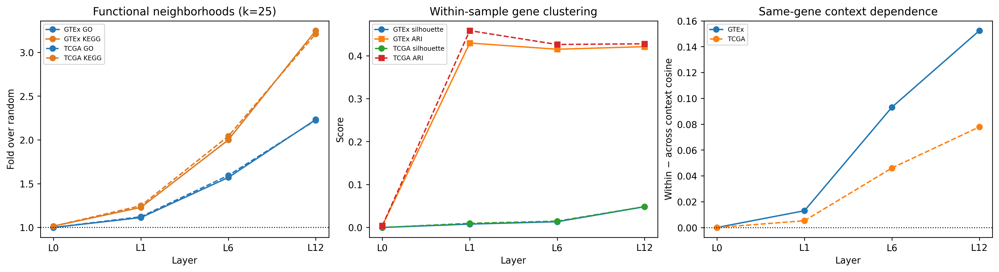

In [22]:
MATCH = HERE / 'results/matched_gtex_tcga'
matched = pd.read_csv(MATCH / 'gtex_tcga_summary.csv')
dependence = pd.read_csv(MATCH / 'context_dependence_summary.csv')
matched_manifest = pd.read_csv(MATCH / 'cohort_manifest.csv')
display(matched_manifest.groupby(['dataset','context']).size().rename('samples').to_frame())
display(Image(filename=str(MATCH / 'gtex_tcga_matched_summary.png')))

## Functional neighborhood replication

The table uses mean-centered cosine and k=25. L0 is evaluated once per dataset
because the pure lookup vector is sample-invariant; contextual layers summarize
all 200 samples per dataset.

In [23]:
layer_order=['L0_static','L1_early','L6_middle','L12_final']
mq=matched[(matched.geometry=='mean_centered_cosine') & (matched.k==25)].copy()
display(mq[['dataset','layer','library','neighbor_fold','neighbor_fold_sd','samples_x']]
 .sort_values(['dataset','library','layer']).style.format({
 'neighbor_fold':'{:.3f}','neighbor_fold_sd':'{:.3f}'}))

,dataset,layer,library,neighbor_fold,neighbor_fold_sd,samples_x
1,GTEx,L0_static,GO,0.999,nan,1
13,GTEx,L12_final,GO,2.232,0.043,200
25,GTEx,L1_early,GO,1.112,0.022,200
37,GTEx,L6_middle,GO,1.570,0.040,200
4,GTEx,L0_static,KEGG,1.014,nan,1
16,GTEx,L12_final,KEGG,3.247,0.074,200
28,GTEx,L1_early,KEGG,1.229,0.036,200
40,GTEx,L6_middle,KEGG,1.999,0.063,200
49,TCGA,L0_static,GO,0.999,nan,1
61,TCGA,L12_final,GO,2.225,0.047,200


GTEx reproduces the TCGA depth trend closely. At k=25, GTEx GO enrichment
increases from 1.00× at L0 to 1.11×, 1.57×, and 2.23× at L1/L6/L12; KEGG
increases from 1.01× to 1.23×, 2.00×, and 3.25×. The matched TCGA values are
1.12×/1.59×/2.22× for GO and 1.25×/2.04×/3.21× for KEGG. Thus the effect
replicates in normal tissues and is not specific to the earlier eight-tumor screen.

## Genome-wide context dependence

For every gene and layer, unit-normalized contextual tokens are accumulated across
all samples. Mean same-gene cosine is calculated exactly for pairs within a tissue
or tumor context and for pairs across contexts. This is a gene-level test, not
sample-level tissue clustering.

In [24]:
display(dependence.style.format({
 'within_context_cosine':'{:.4f}','across_context_cosine':'{:.4f}',
 'within_minus_across':'{:.4f}','genes_positive_difference':'{:.1%}'}))

,dataset,layer,within_context_cosine,across_context_cosine,within_minus_across,genes_positive_difference
0,GTEx,L0_static,1.0000,1.0000,-0.0000,49.9%
1,GTEx,L1_early,0.9975,0.9846,0.0130,100.0%
2,GTEx,L6_middle,0.9927,0.8996,0.0931,100.0%
3,GTEx,L12_final,0.9844,0.8320,0.1524,100.0%
4,TCGA,L0_static,1.0000,1.0000,-0.0000,49.9%
5,TCGA,L1_early,0.9948,0.9896,0.0052,100.0%
6,TCGA,L6_middle,0.9827,0.9367,0.0460,100.0%
7,TCGA,L12_final,0.9626,0.8847,0.0778,100.0%


L0 has no context dependence, as required for a sample-invariant lookup.
At every contextual layer, all genes have higher average within-context than
across-context similarity. Separation grows with depth and is larger in GTEx:
0.013, 0.093, and 0.152 at L1/L6/L12, compared with 0.005, 0.046, and 0.078
in TCGA. This suggests that normal-tissue identity produces stronger context-
specific gene geometry than the selected tumor contexts.

## Contextual gene clustering

Within each sample, centered unit-normalized gene tokens are clustered with
spherical k-means (`k=10`) under two seeds. Silhouette and ARI quantify geometric
separation and initialization stability. Enrichment is calculated from the same
assignments against the model gene universe; `significant_terms` is the mean sum
of FDR-significant terms across the ten clusters per sample.

In [25]:
cq=(mq.groupby(['dataset','layer'],as_index=False)
    .agg(silhouette=('silhouette','first'),stability_ari=('stability_ari','first'),
         mean_significant_go=('significant_terms',lambda x: x[mq.loc[x.index,'library'].eq('GO')].mean()),
         mean_significant_kegg=('significant_terms',lambda x: x[mq.loc[x.index,'library'].eq('KEGG')].mean())))
display(cq.style.format({'silhouette':'{:.4f}','stability_ari':'{:.3f}',
 'mean_significant_go':'{:.1f}','mean_significant_kegg':'{:.1f}'}))

,dataset,layer,silhouette,stability_ari,mean_significant_go,mean_significant_kegg
0,GTEx,L0_static,-0.0006,0.004,0.0,0.0
1,GTEx,L12_final,0.0479,0.421,1843.8,365.3
2,GTEx,L1_early,0.0073,0.430,388.3,86.9
3,GTEx,L6_middle,0.0129,0.415,1392.1,273.6
4,TCGA,L0_static,-0.0006,0.004,0.0,0.0
5,TCGA,L12_final,0.0482,0.428,1761.8,343.6
6,TCGA,L1_early,0.0091,0.459,437.0,94.1
7,TCGA,L6_middle,0.0142,0.426,1383.1,263.7


Global gene clusters remain only weakly separated—the L12 silhouette is
approximately 0.048—but become substantially more reproducible after
contextualization (ARI ≈ 0.42–0.46 versus ≈ 0.004 at L0) and carry many adjusted
GO/KEGG associations. This is consistent with overlapping functional modules:
functionally coherent local and cluster structure can increase without producing
well-separated spherical clouds.

## Matched visualizations

A fixed set of 2,000 genes is used in both datasets. For each layer, GTEx and TCGA
are fit jointly with PCA-50 and jointly projected with identical t-SNE and UMAP
parameters and seed. Colors are fixed clusters from the average of the matched
GTEx and TCGA gene representations. These panels are qualitative only.

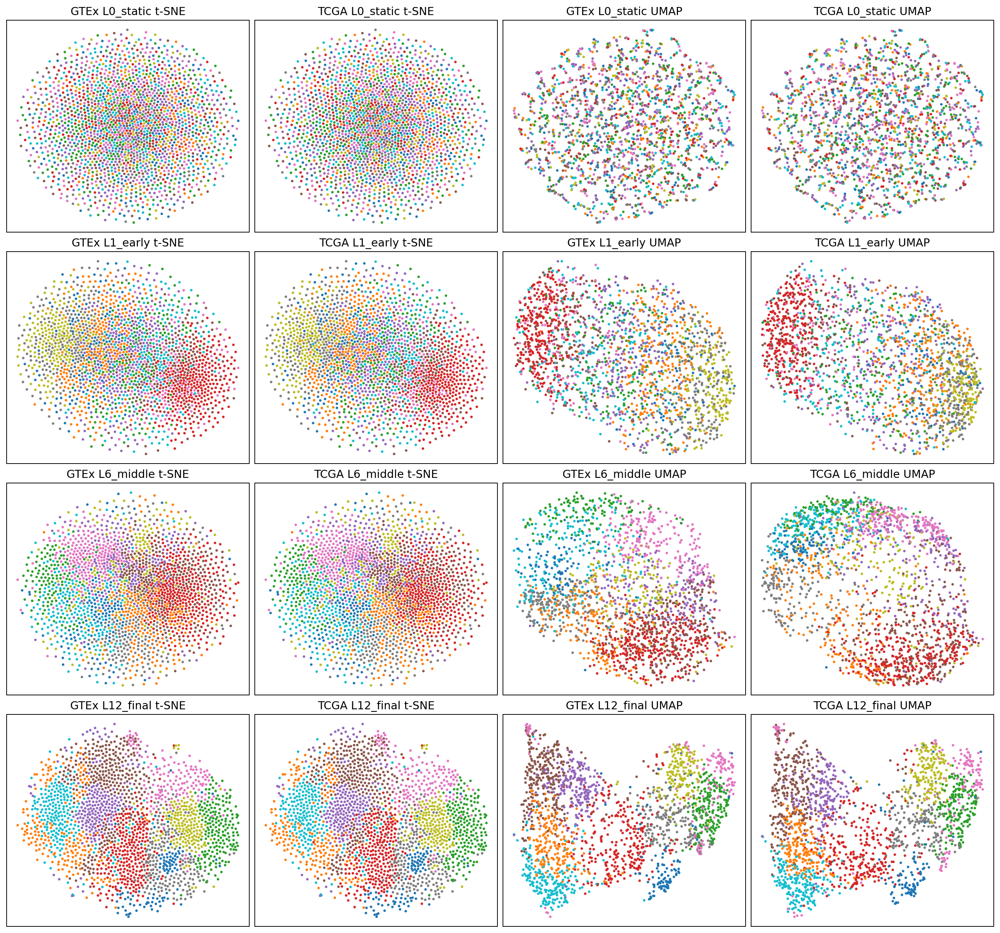

In [26]:
display(Image(filename=str(MATCH / 'matched_contextual_projections.png'))) 

## Cross-cohort conclusion

The balanced GTEx cohort independently reproduces the L0→L12 increase in GO and
KEGG neighborhood organization seen in TCGA. Static L0 remains sample-invariant,
near-null, and unstable under clustering. Contextual representations progressively
develop functional neighborhoods, more stable gene modules, and context-specific
same-gene states. GTEx and TCGA have remarkably similar functional-depth curves,
but GTEx develops stronger tissue-specific same-gene separation.

Together, the evidence supports the hypothesis that the lookup table primarily
provides gene identity, while the transformer combines that identity with the
sample expression state to create biologically organized, context-dependent gene
representations. The result remains exploratory because annotation overlap is not
an independent downstream phenotype, tumor and normal contexts are not paired,
and the clustering model imposes spherical modules on overlapping biology.

# Cohort-level contextual gene modules and TPM controls

The preceding within-sample analysis asks whether a particular expression state
contains gene modules. This complementary analysis averages each gene's 512-D
token across the same 200 balanced samples, separately for GTEx and TCGA, and then
clusters the resulting 15,165 original vectors. K-means is fit in 512 dimensions;
t-SNE and UMAP are display-only.

For every dataset/layer, ordinary Euclidean K-means uses `k=10`, five seeds, and
10 initializations per seed. Stability is mean pairwise ARI. GO and KEGG use the
same canonical model background and BH correction within cluster/library.

In [27]:
MOD = HERE / 'results/contextual_gene_modules'
modules = pd.read_csv(MOD / 'contextual_gene_module_summary.csv')
controls = pd.read_csv(MOD / 'expression_control_summary.csv')
display(modules[['dataset','layer','silhouette','stability_ari','min_cluster_size',
 'max_cluster_size','significant_go_terms','significant_kegg_terms','top_go_term',
 'top_kegg_term']].style.format({'silhouette':'{:.4f}','stability_ari':'{:.3f}'}))

,dataset,layer,silhouette,stability_ari,min_cluster_size,max_cluster_size,significant_go_terms,significant_kegg_terms,top_go_term,top_kegg_term
0,GTEx,L0_static,0.0009,0.006,1150,1670,1,1,Lymphocyte Differentiation (GO:0030098),CELLULAR SENESCENCE
1,GTEx,L1_early,0.0015,0.279,932,1730,296,86,Chemical Synaptic Transmission (GO:0007268),NEUROACTIVE LIGAND-RECEPTOR INTERACTION
2,GTEx,L6_middle,-0.0054,0.672,779,2012,1512,328,Mitochondrial Translation (GO:0032543),RIBOSOME
3,GTEx,L12_final,0.0280,0.779,891,2175,2305,374,Steroid Metabolic Process (GO:0008202),CORNIFIED ENVELOPE FORMATION
4,TCGA,L0_static,0.0009,0.006,1150,1670,1,1,Lymphocyte Differentiation (GO:0030098),CELLULAR SENESCENCE
5,TCGA,L1_early,0.0019,0.348,700,2010,467,120,Cytoplasmic Translation (GO:0002181),RIBOSOME
6,TCGA,L6_middle,-0.0038,0.617,1112,1800,1544,259,Chromatin Remodeling (GO:0006338),NUCLEOCYTOPLASMIC TRANSPORT
7,TCGA,L12_final,0.0245,0.850,1003,1843,2239,366,Protein Ubiquitination (GO:0016567),UBIQUITIN MEDIATED PROTEOLYSIS


Module stability and functional enrichment increase strongly with depth in
both datasets. L0 is unstable (ARI ≈ 0.006) and has only one adjusted GO and KEGG
term. At L12, ARI reaches 0.779 in GTEx and 0.850 in TCGA, with thousands of GO
and hundreds of KEGG discoveries. Silhouette remains low (≈0.02–0.03), again
indicating stable overlapping biological partitions rather than sharply separated
geometric islands.

## Matched projections colored by 512-D module

GTEx and TCGA are jointly fit with PCA-50 and jointly projected per layer using
identical t-SNE/UMAP settings. Color is the cohort-specific K-means assignment
obtained from the original 512-D vectors. Cluster numbers are arbitrary and are
not homologous across datasets or layers even when colors match.

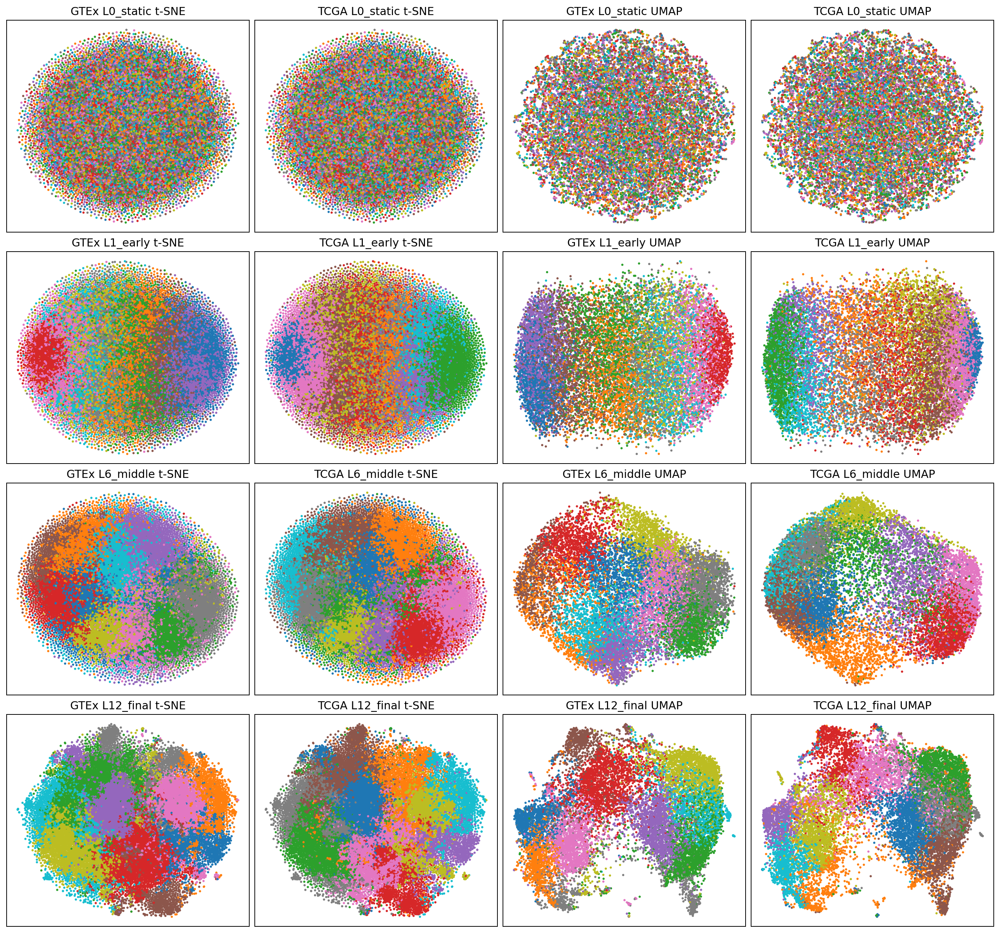

In [28]:
display(Image(filename=str(MOD / 'matched_projections_by_clusters.png'))) 

## The same projections colored by expression

The coordinates below are identical to the cluster-colored panels; only color is
changed to cohort mean natural `log1p(TPM)`. This reveals how much of the visible
geometry follows expression level.

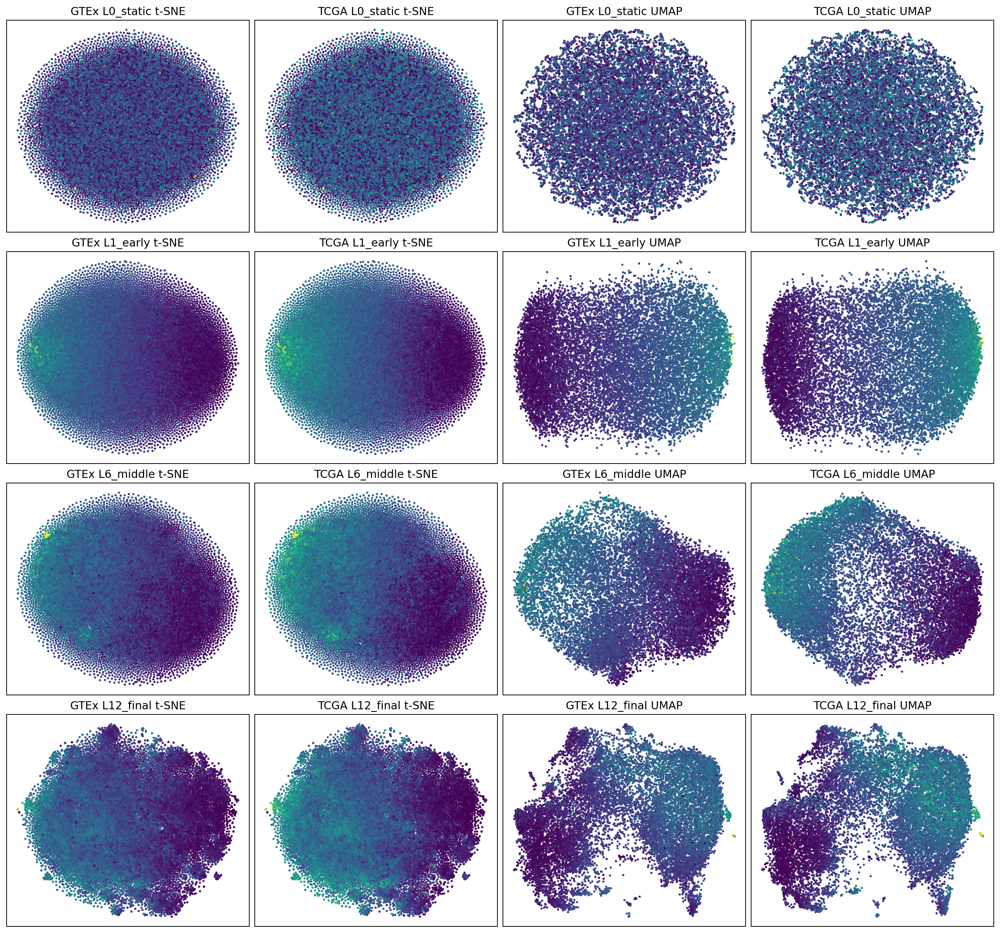

In [29]:
display(Image(filename=str(MOD / 'matched_projections_by_expression.png'))) 

## Geometry after linear TPM residualization

These matched panels repeat joint PCA-50, t-SNE, and UMAP after regressing cohort-mean
`log1p(TPM)` linearly from every embedding dimension. Colors in the first figure are
new K-means assignments fitted in the residual 512-D space; they are not aligned across
cohorts or layers. The second figure uses the original mean `log1p(TPM)` values to show
how much expression ordering remains after the linear adjustment. Residualization does
not remove nonlinear expression effects, and the projections remain exploratory.

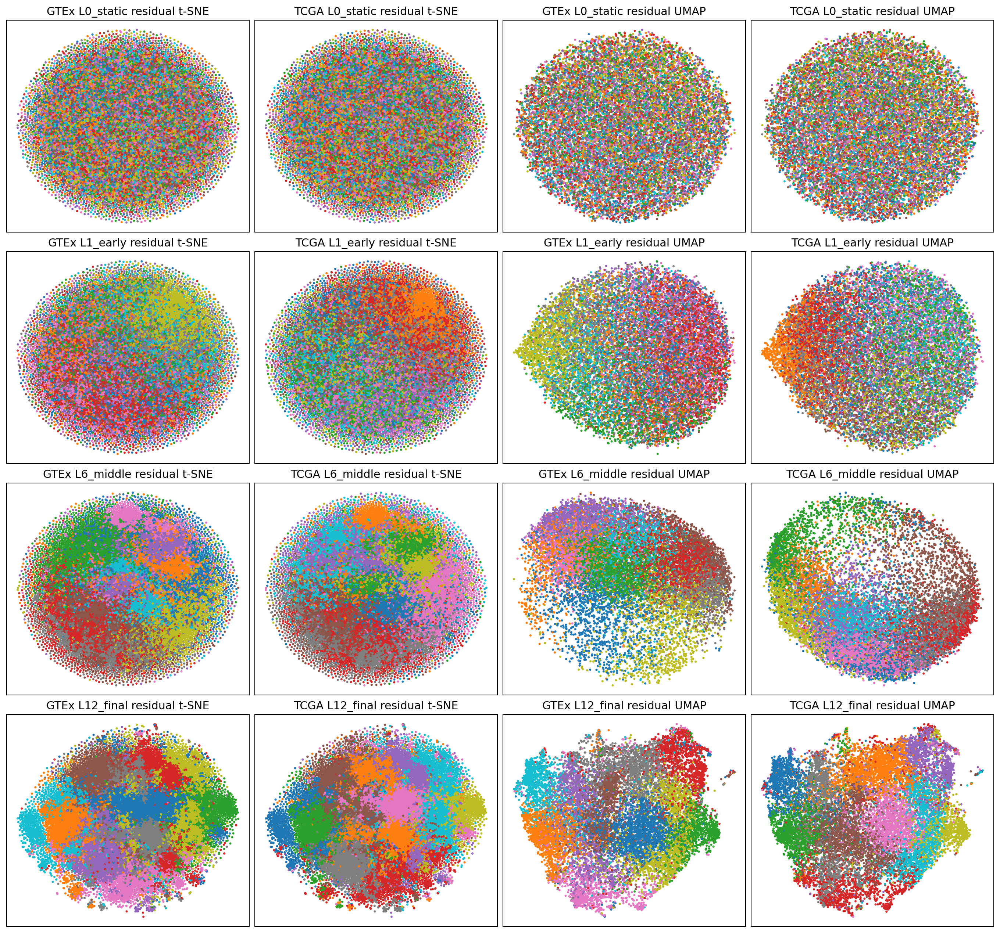

In [30]:
display(Image(filename=str(MOD / 'matched_tpm_residual_projections_by_clusters.png'))) 

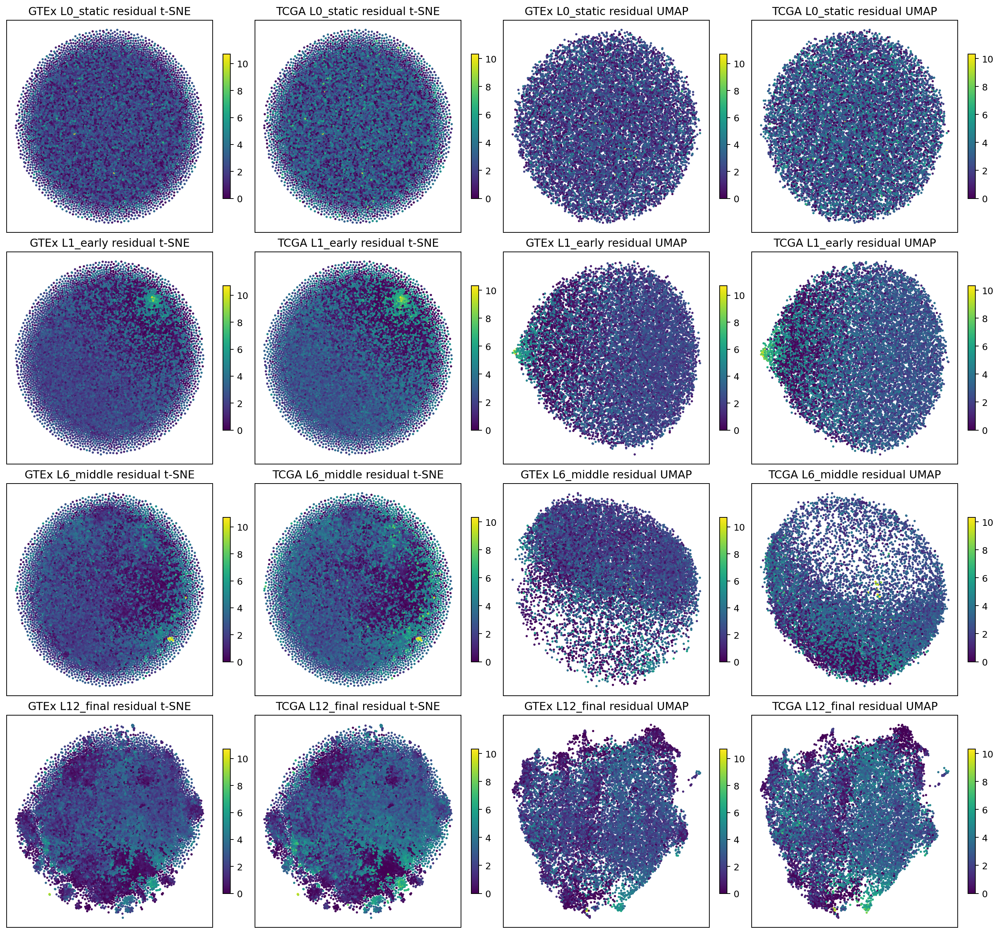

In [31]:
display(Image(filename=str(MOD / 'matched_tpm_residual_projections_by_expression.png'))) 

## Quantifying TPM dependence

Four complementary diagnostics are used:

- Spearman correlation between embedding norm and mean `log1p(TPM)`.
- Spearman correlation between pairwise cosine similarity and negative absolute
  expression difference across 200,000 random gene pairs.
- Cluster effect size for TPM (η²) and NMI with expression deciles.
- Mean TPM difference among top-25 embedding neighbors relative to random pairs.


In [32]:
display(modules[['dataset','layer','norm_tpm_spearman',
 'pair_cosine_expression_similarity_spearman','cluster_tpm_eta_squared',
 'cluster_expression_bin_nmi','neighbor_expression_difference_ratio']]
 .style.format({c:'{:.3f}' for c in ['norm_tpm_spearman',
 'pair_cosine_expression_similarity_spearman','cluster_tpm_eta_squared',
 'cluster_expression_bin_nmi','neighbor_expression_difference_ratio']}))

,dataset,layer,norm_tpm_spearman,pair_cosine_expression_similarity_spearman,cluster_tpm_eta_squared,cluster_expression_bin_nmi,neighbor_expression_difference_ratio
0,GTEx,L0_static,0.038,0.002,0.000,0.001,0.989
1,GTEx,L1_early,-0.411,0.389,0.860,0.408,0.593
2,GTEx,L6_middle,-0.438,0.339,0.693,0.257,0.700
3,GTEx,L12_final,-0.625,0.537,0.699,0.266,0.400
4,TCGA,L0_static,0.040,0.002,0.000,0.001,0.987
5,TCGA,L1_early,-0.536,0.402,0.905,0.473,0.555
6,TCGA,L6_middle,-0.530,0.322,0.777,0.317,0.661
7,TCGA,L12_final,-0.506,0.564,0.770,0.315,0.354


TPM is an important organizing variable after contextualization. At L12,
cluster membership explains approximately 70% of GTEx and 77% of TCGA mean-TPM
variance; similar-expression genes also have higher cosine similarity, and top-25
neighbors differ in expression by only 40% (GTEx) or 35% (TCGA) of the random-pair
difference. The modules therefore cannot be described as expression-independent.

## Is functional organization reducible to TPM?

Two controls address this directly. First, genes are divided into ten equal-sized
mean-expression bins and those bins are tested for enrichment. Second, mean
`log1p(TPM)` is linearly regressed from every one of the 512 embedding dimensions;
the residual vectors are reclustered with the same K-means parameters. Linear
residualization is conservative but does not remove nonlinear expression effects.

In [33]:
display(controls.style.format({'silhouette':'{:.4f}',
                                       'stability_ari':'{:.3f}'}))

,dataset,control,significant_go_terms,significant_kegg_terms,layer,silhouette,stability_ari
0,GTEx,expression_deciles,382,73,nan,nan,nan
1,GTEx,linear_tpm_residual,0,0,L0_static,0.0006,0.006
2,GTEx,linear_tpm_residual,59,22,L1_early,0.0011,0.097
3,GTEx,linear_tpm_residual,1945,302,L6_middle,-0.0080,0.434
4,GTEx,linear_tpm_residual,2229,305,L12_final,0.0193,0.927
5,TCGA,expression_deciles,493,98,nan,nan,nan
6,TCGA,linear_tpm_residual,0,0,L0_static,0.0006,0.007
7,TCGA,linear_tpm_residual,69,35,L1_early,0.0009,0.115
8,TCGA,linear_tpm_residual,1773,274,L6_middle,-0.0069,0.457
9,TCGA,linear_tpm_residual,2192,280,L12_final,0.0160,0.859


Expression deciles alone are biologically enriched (382/73 GO/KEGG terms in
GTEx and 493/98 in TCGA), confirming that abundance is a genuine biological
confound. However, the L12 TPM-residual modules retain 2,229/305 significant
GO/KEGG terms in GTEx and 2,192/280 in TCGA, with ARI 0.927 and 0.859. Most of
the functional organization therefore survives removal of the linear TPM axis.

The supported interpretation is nuanced: contextualization organizes genes partly
by expression magnitude, but the reproducible and functionally coherent L12
modules are not primarily reducible to that magnitude. Functional enrichment and
module stability remain strong after explicit TPM residualization in both normal
tissue and tumors.

# Matched Pearson/Spearman coexpression baseline

This comparison asks whether Bridge recovers functional neighborhoods beyond a
straightforward correlation network. For each frozen 200-sample cohort, Pearson
and Spearman correlations are calculated between genes using the same natural
`log1p(TPM)` matrix and canonical gene ordering. Bridge uses one cohort-mean
512-D contextual vector per gene, with mean-centered cosine similarity, so every
method defines one cohort-level network.

For every method, the top 10, 25, and 50 neighbors are evaluated with the same GO
and KEGG definitions. The score is the aggregate fraction of annotation-eligible
query-neighbor pairs sharing at least one annotation, divided by a shared random-
neighbor null. Error bars are 95% intervals from gene bootstrapping combined with
null-replicate sampling. Constant-expression genes have undefined correlations and
are excluded from all methods within that cohort; the exact losses are reported.

In [34]:
COEX = HERE / 'results/coexpression_baseline'
coex = pd.read_csv(COEX / 'coexpression_vs_bridge_summary.csv')
eligibility = pd.read_csv(COEX / 'gene_eligibility.csv')
primary = pd.read_csv(COEX / 'primary_k25_comparison.csv')
display(eligibility)
display(primary.style.format({
    'Bridge L0':'{:.3f}', 'Bridge L1':'{:.3f}', 'Bridge L6':'{:.3f}',
    'Bridge L12':'{:.3f}', 'Pearson':'{:.3f}', 'Spearman':'{:.3f}',
    'L12_minus_best_coexpression':'{:.3f}',
    'L12_over_best_coexpression':'{:.3f}',
}))

,dataset,canonical_genes,eligible_variable_genes,excluded_constant_genes
0,GTEx,15165,15037,128
1,TCGA,15165,15105,60


,dataset,library,Bridge L0,Bridge L1,Bridge L12,Bridge L6,Pearson,Spearman,L12_minus_best_coexpression,L12_over_best_coexpression
0,GTEx,GO,0.998,1.104,2.412,1.588,2.000,1.895,0.412,1.206
1,GTEx,KEGG,1.018,1.221,3.612,2.048,2.973,2.708,0.639,1.215
2,TCGA,GO,0.999,1.128,2.359,1.613,2.038,1.958,0.321,1.157
3,TCGA,KEGG,1.018,1.294,3.515,2.127,2.796,2.597,0.719,1.257


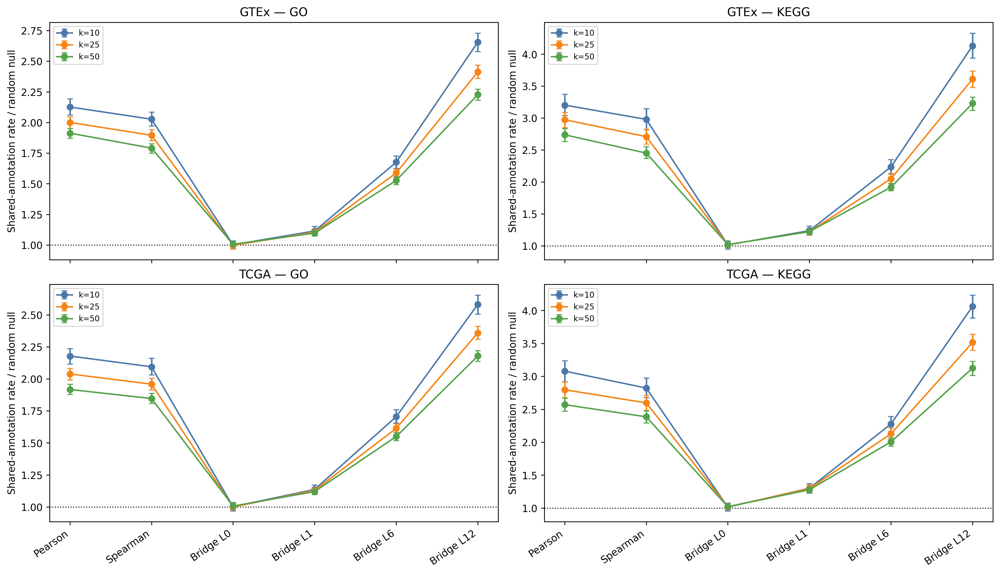

In [35]:
display(Image(filename=str(COEX / 'matched_coexpression_vs_bridge.png'))) 

Across k=10/25/50, Bridge L12 exceeds both correlation baselines for GO and
KEGG in both cohorts. At k=25, L12 is 1.206× and 1.215× the better coexpression
baseline for GTEx GO and KEGG, respectively, and 1.157× and 1.257× for TCGA.
Pearson is consistently stronger than Spearman here, while L0 is at the random
baseline and L1 remains below ordinary coexpression. The advantage emerges between
L6 and L12 and replicates in normal and tumor transcriptomes.

This is evidence that L12 contains functional-neighborhood information not recovered
by pairwise coexpression alone, but it is not evidence that expression is irrelevant:
Bridge receives the complete expression state and can encode nonlinear, multigene,
and tissue-dependent relationships. This cohort-level comparison is deliberately
distinct from the earlier per-sample contextual-occurrence endpoint.

# Does L12 add information beyond coexpression and expression level?

The conditional analysis uses the same sampled gene pairs in both cohorts. The
binary outcome is whether two annotation-eligible genes share at least one GO
Biological Process term or KEGG pathway. A base logistic model contains Pearson
coexpression, Spearman coexpression, pair-average cohort mean `log1p(TPM)`, and
absolute difference in mean expression. The full model adds mean-centered L12
cosine similarity.

Coefficient inference uses sandwich standard errors clustered by anchor gene.
Predictive effects are evaluated out of sample with five-fold anchor-gene grouped
cross-validation. Confidence intervals for AUROC/AUPRC changes resample anchor
genes, preventing pairs from the same anchor from being treated as independent.

In [36]:
COND = HERE / 'results/l12_conditional_function'
conditional = pd.read_csv(COND / 'l12_conditional_results.csv')
display(conditional[['dataset','library','pairs','positive_fraction',
 'l12_odds_ratio_per_sd','l12_or_ci_low','l12_or_ci_high','l12_p_value',
 'base_auroc','full_auroc','delta_auroc','delta_auroc_ci_low','delta_auroc_ci_high',
 'base_auprc','full_auprc','delta_auprc','delta_auprc_ci_low','delta_auprc_ci_high']]
 .style.format({c:'{:.4f}' for c in ['positive_fraction','base_auroc','full_auroc',
 'delta_auroc','delta_auroc_ci_low','delta_auroc_ci_high','base_auprc',
 'full_auprc','delta_auprc','delta_auprc_ci_low','delta_auprc_ci_high']}
 | {c:'{:.3f}' for c in ['l12_odds_ratio_per_sd','l12_or_ci_low','l12_or_ci_high']}
 | {'l12_p_value':'{:.2e}'}))

,dataset,library,pairs,positive_fraction,l12_odds_ratio_per_sd,l12_or_ci_low,l12_or_ci_high,l12_p_value,base_auroc,full_auroc,delta_auroc,delta_auroc_ci_low,delta_auroc_ci_high,base_auprc,full_auprc,delta_auprc,delta_auprc_ci_low,delta_auprc_ci_high
0,GTEx,GO,211187,0.0701,1.223,1.193,1.254,5.08e-56,0.5550,0.5728,0.0177,0.0131,0.0223,0.0862,0.0916,0.0054,0.0041,0.0070
1,GTEx,KEGG,56416,0.0529,1.424,1.347,1.505,7.36e-36,0.5329,0.5851,0.0522,0.0377,0.0666,0.0635,0.0795,0.0159,0.0107,0.0211
2,TCGA,GO,211187,0.0701,1.188,1.156,1.220,9.71e-37,0.5684,0.5792,0.0108,0.0076,0.0144,0.0904,0.0937,0.0033,0.0021,0.0045
3,TCGA,KEGG,56416,0.0529,1.404,1.326,1.485,7.68e-32,0.5569,0.5929,0.0360,0.0249,0.0469,0.0678,0.0804,0.0126,0.0080,0.0180


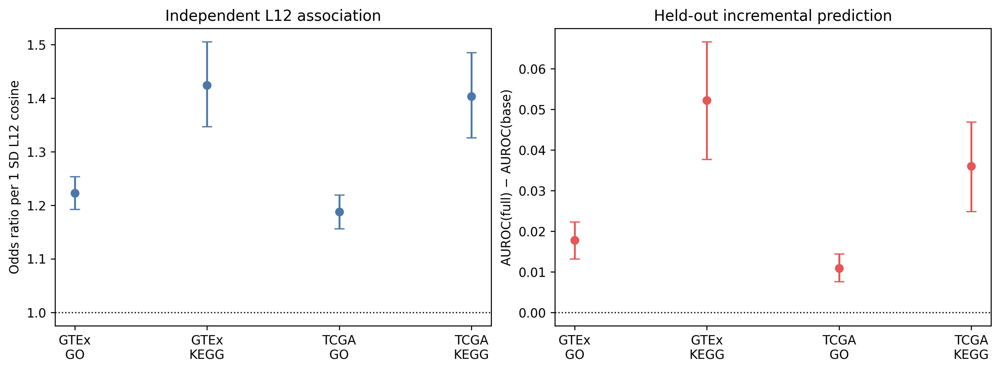

In [37]:
display(Image(filename=str(COND / 'l12_conditional_function.png'))) 

L12 contributes significant information after the specified controls in
both cohorts. Adjusted odds ratios per 1-SD L12 cosine are 1.223 (95% CI
1.193–1.254) for GTEx GO, 1.424 (1.347–1.505) for GTEx KEGG, 1.188
(1.156–1.220) for TCGA GO, and 1.404 (1.326–1.485) for TCGA KEGG. Cluster-robust
p-values range from approximately 8×10⁻³² to 5×10⁻⁵⁶.

Adding L12 increases held-out AUROC by 0.0177 for GTEx GO, 0.0522 for GTEx KEGG,
0.0108 for TCGA GO, and 0.0360 for TCGA KEGG; every 95% anchor-bootstrap interval
is above zero. AUPRC also increases in all four analyses. The independent signal
therefore replicates, with a larger effect for KEGG than GO.

This supports an incremental—not causal—claim. The model controls linear Pearson,
Spearman, and mean-expression terms, but L12 is itself derived from the full
expression profile; nonlinear or higher-order expression structure can legitimately
mediate its additional information. Shared database annotations are also not an
independent experimental endpoint.

# Paper summary figure

The four-panel summary combines the primary quantitative evidence: functional
neighborhoods across depth, the matched coexpression comparison, the conditional
L12 effect after expression controls, and retention of L12 module organization
after linear TPM removal. Panel D reports residual/original percentages so GO,
KEGG, and stability are comparable without mixing arbitrary scales.

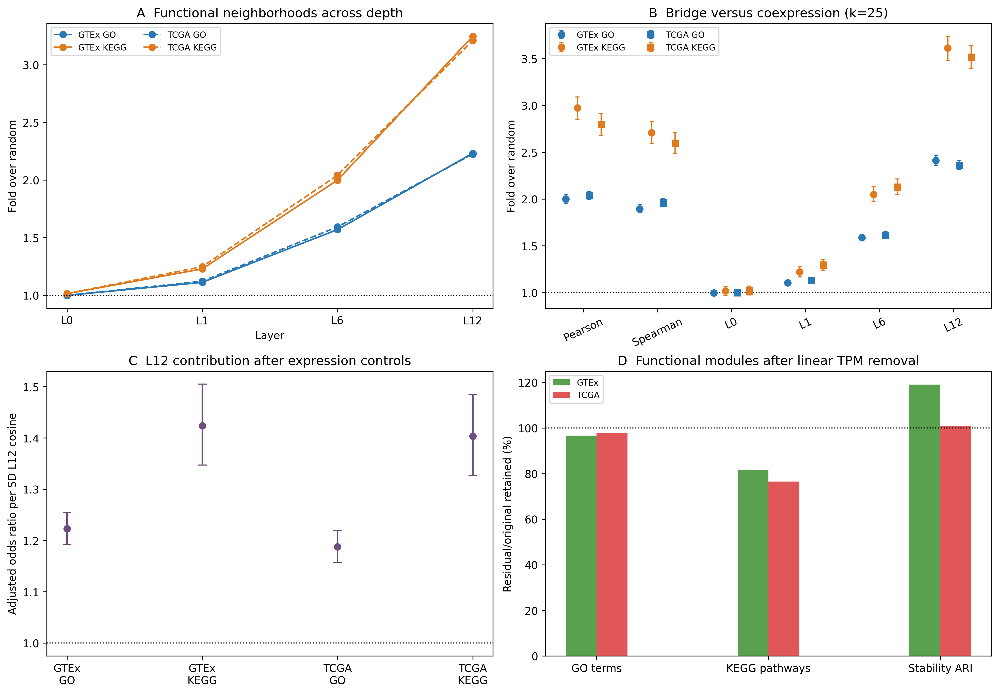

In [38]:
PAPER = HERE / 'results/paper_summary'
display(Image(filename=str(PAPER / 'bridge_contextual_biology_summary.png')))

# Gene-level contextual shifts colored by tissue or tumor context

Each point below is one of 500 fixed genes in one tissue/tumor context. For each
context, its gene token is averaged across two frozen representative samples. To
make context colors interpretable rather than letting static gene identity dominate,
each gene's mean vector across contexts is subtracted within cohort and layer before
joint PCA-50, t-SNE, and UMAP.

L0 residuals are exactly zero because static embeddings are context invariant.
From L1 onward, tissue-dependent shifts appear and become especially separated at
L6. L12 retains substantial context organization but is not uniformly more separated
than L6. These projections are exploratory: context residualization intentionally
emphasizes between-context variation, only two samples represent each context, and
t-SNE/UMAP separation is not a quantitative effect size.

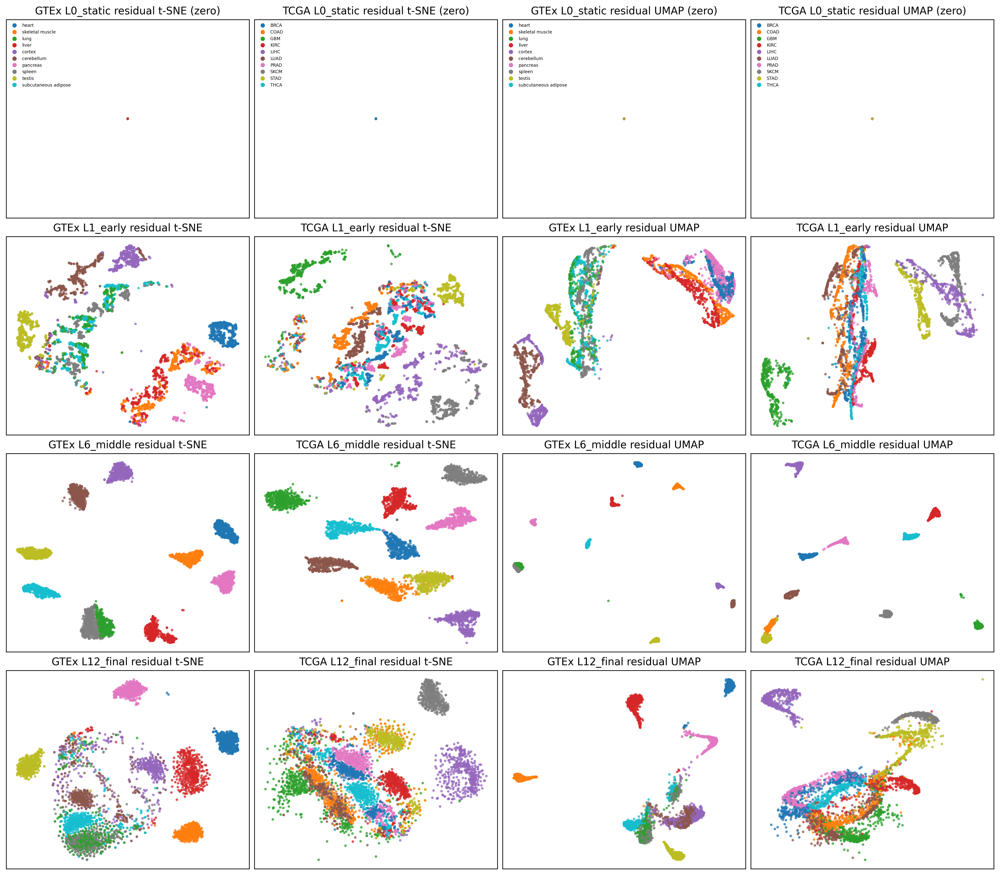

In [39]:
CTX = HERE / 'results/context_colored_gene_projections'
display(Image(filename=str(CTX / 'gene_context_residuals_colored_by_tissue.png')))

## Horizontal UMAP view

The same saved context-residual UMAP coordinates are displayed with layers running
left to right and separate GTEx and TCGA rows. Gene selection, context colors, and
projection coordinates are unchanged. L0 is shown as one neutral point because all
residuals coincide at zero. Context organization is visible after L0, but these
exploratory projections of two representative samples per context do not quantify
biological separation.

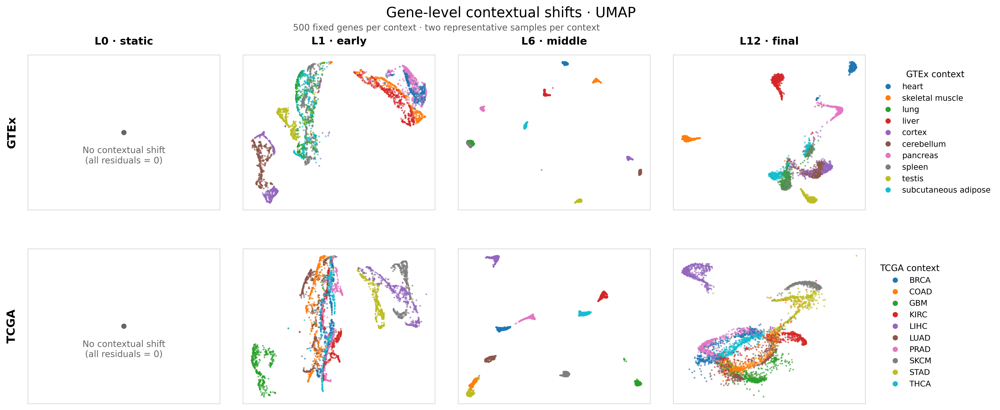

In [40]:
display(Image(filename=str(CTX / 'gene_context_residuals_umap_horizontal.png')))